# Freeform beam shaping

A beam shaper takes the light it is given and puts it where it is
wanted: a Gaussian laser beam into a flat top for materials processing, an
LED into a rectangular patch on a road, or a collimated beam into a
picture on a wall. Without symmetry the optical surface becomes a
freeform. This notebook builds such shapers from scratch with the
geometric-optics approach, where each ray carries a fixed share of the
power and the design problem is to decide where each ray goes.

The sections are:

1. the ray map of a rotationally symmetric shaper from equal enclosed
   power, and soft-edged (Fermi–Dirac) flat tops,
2. the classic two-lens Gaussian to flat-top shaper: its two aspheres in
   closed form, a ray trace of the result, and what a wrong input beam
   size does,
3. wave optics behind the shaper: why a flat top should not have a sharp
   edge,
4. freeform shaping without symmetry: the Monge–Ampère equation, its
   solution by optimal transport, and a plano-freeform lens that turns a
   round Gaussian into a square flat top,
5. the same lens for an arbitrary target, a picture,
6. what a real source does to it: divergence, étendue and blur.

The functions are in `pyoptics.freeform`: `radial_map()`,
`fermi_dirac()`, `flattop_shaper()`, `ot_map()`, `integrate_gradient()`,
`freeform_lens()` and the surface `TabulatedSurface`, which puts a
tabulated sag (radial or on an x–y grid) into a `pyoptics.raytrace`
system. Lengths are in mm.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

from pyoptics import freeform as ff
from pyoptics import illumination as il
from pyoptics import raytrace as rt
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(89)

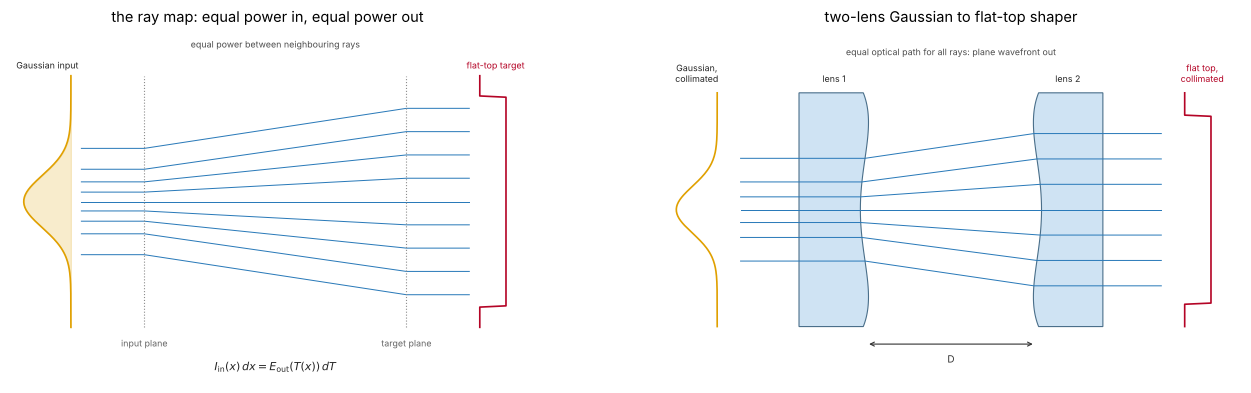

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.8), layout="constrained")
sketch.beam_shaping_ray_map(ax[0], title="the ray map: equal power in, equal power out")
sketch.flattop_beam_shaper(ax[1], title="two-lens Gaussian to flat-top shaper")
plt.show()

## 1. The ray map

Geometric optics treats a beam as a bundle of rays. Without absorption,
the power in a tube of rays is the same before and behind the shaper. For a
rotationally symmetric shaper the ray at the input radius $r$ goes to the
output radius $R(r)$, and the power inside $r$ must equal the power
inside $R$:

$$\int_0^r I_\mathrm{in}(r')\,r'\,\mathrm{d}r' = \int_0^{R(r)} E_\mathrm{out}(R')\,R'\,\mathrm{d}R',$$

with both profiles normalized to the same total. This fixes $R(r)$
completely. A Gaussian $I_\mathrm{in} = \exp(-2r^2/w^2)$ cut at $2w$ and a
sharp flat top of radius $R_0$ give

$$R(r) = R_0\sqrt{\frac{1 - \exp(-2r^2/w^2)}{1 - \exp(-8)}}.$$

A flat top with a perfectly sharp edge diffracts badly (section 3). The
usual remedy is a soft edge, for example the Fermi–Dirac profile

$$E_\mathrm{out}(R) = \frac{1}{1 + \exp\left(\beta(R/R_0 - 1)\right)},$$

which falls from 88 % to 12 % over $4R_0/\beta$. Here $w = 2$ mm and
$R_0 = 3$ mm.

In [3]:
W_IN, R_0 = 2.0, 3.0                 # mm: 1/e^2 radius of the Gaussian, radius of the flat top
r = np.linspace(0, 2*W_IN, 2001)     # the input beam is used out to 2 w (99.97 % of the power)
I_in = np.exp(-2*r**2/W_IN**2)
R_grid = np.linspace(0, 1.8*R_0, 4001)
betas = [10, 20, 60]
maps = {b: ff.radial_map(r, I_in, R_grid, ff.fermi_dirac(R_grid, R_0, b)) for b in betas}
R_sharp = R_0*np.sqrt((1 - np.exp(-2*r**2/W_IN**2))/(1 - np.exp(-8.0)))
R_sharp_num = ff.radial_map(r, I_in, np.linspace(0, R_0, 4001), np.ones(4001))
print("sharp flat top: numerical map against R_0 sqrt((1 - exp(-2r^2/w^2))/(1 - exp(-8))): max difference {:.1e} mm".format(
    np.max(np.abs(R_sharp_num - R_sharp))))
for b in betas:
    print("beta = {:2d}: edge from 88 % to 12 % over {:.2f} mm; the ray at r = w lands at R = {:.2f} mm".format(
        b, 4*R_0/b, np.interp(W_IN, r, maps[b])))

sharp flat top: numerical map against R_0 sqrt((1 - exp(-2r^2/w^2))/(1 - exp(-8))): max difference 1.5e-05 mm
beta = 10: edge from 88 % to 12 % over 1.20 mm; the ray at r = w lands at R = 3.05 mm
beta = 20: edge from 88 % to 12 % over 0.60 mm; the ray at r = w lands at R = 2.84 mm
beta = 60: edge from 88 % to 12 % over 0.20 mm; the ray at r = w lands at R = 2.79 mm


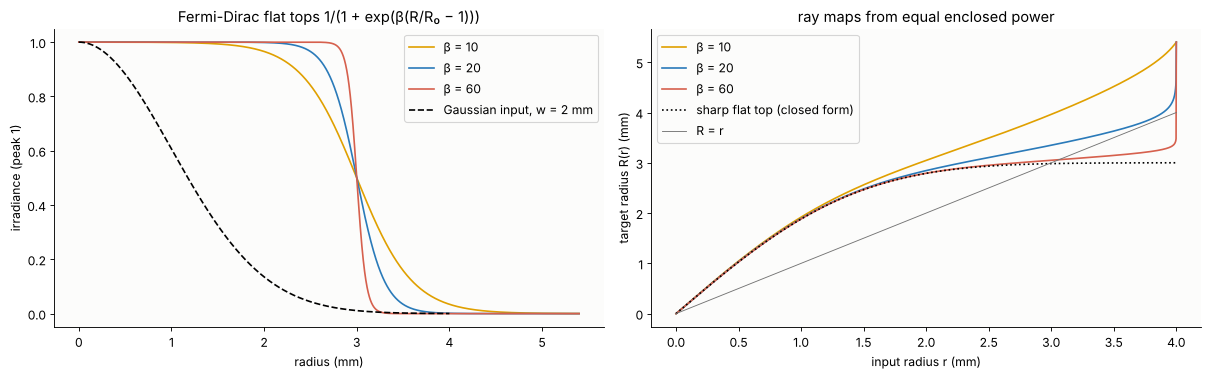

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
for b, c in zip(betas, (ORANGE, BLUE, RED)):
    ax[0].plot(R_grid, ff.fermi_dirac(R_grid, R_0, b), color=c, label="β = {}".format(b))
    ax[1].plot(r, maps[b], color=c, label="β = {}".format(b))
ax[0].plot(r, I_in, color="k", ls="--", label="Gaussian input, w = 2 mm")
ax[0].set_xlabel("radius (mm)")
ax[0].set_ylabel("irradiance (peak 1)")
ax[0].set_title("Fermi-Dirac flat tops 1/(1 + exp(β(R/R₀ − 1)))")
ax[0].legend()
ax[1].plot(r, R_sharp, color="k", ls=":", label="sharp flat top (closed form)")
ax[1].plot(r, r, color=GREY, lw=0.8, label="R = r")
ax[1].set_xlabel("input radius r (mm)")
ax[1].set_ylabel("target radius R(r) (mm)")
ax[1].set_title("ray maps from equal enclosed power")
ax[1].legend()
plt.show()

The numerical map matches the closed form for the sharp flat top to
1.5e-5 mm. The edge of the flat top is 1.2 mm wide for $\beta = 10$,
0.6 mm for $\beta = 20$ and 0.2 mm for $\beta = 60$. Softer edges need a
little more room, so the ray at $r = w$ lands at 3.05 mm, 2.84 mm and
2.79 mm. All maps push the rays near the axis outwards (the centre of the
Gaussian is too bright) and pull the rays in the wings inwards.

## 2. The two-lens flat-top shaper

The classic design (Kreuzer; Hoffnagle and Jefferson) has two aspheric
surfaces a distance $D$ apart. The first one refracts the ray at $r$ so
that it hits the second one at $R(r)$. The second one makes it parallel
to the axis again. The output is then a collimated flat top with a plane
wavefront, which a single surface cannot give.

Both surfaces follow from two conditions. Every ray has the same optical
path from the input plane to the output plane, and so the wavefront stays
plane. With glass of index $n$ before the first surface and behind the
second one and air in between, the extra gap $u = z_2(R) - z_1(r)$
satisfies

$$(n^2 - 1)\,u^2 + 2D(n - 1)\,u - (R - r)^2 = 0,$$

and Snell's law at the first surface gives its slope

$$\frac{\mathrm{d}z_1}{\mathrm{d}r} = \frac{\sin\theta}{n - \cos\theta},\qquad \sin\theta = \frac{R - r}{\sqrt{(R - r)^2 + (D + u)^2}},$$

where $\theta$ is the ray angle in the gap. Here $D = 100$ mm, $n = 1.5$,
the edge is $\beta = 20$, and the surfaces are traced as
`TabulatedSurface`s with a million Gaussian distributed rays. The last
panel feeds the shaper with beams 10 % smaller and larger than the design
beam.

In [5]:
N_GLASS, D_GAP, WL = 1.5, 100.0, 532e-6
BETA = 20
R_of_r = maps[BETA]
z_1, z_2 = ff.flattop_shaper(r, R_of_r, N_GLASS, D_GAP)
print("lens 1: sag at r = 2w {:+.1f} um, lens 2: sag at R = {:.2f} mm {:+.1f} um".format(1e3*z_1[-1], R_of_r[-1], 1e3*z_2[-1]))

def shaper(z1=z_1, z2=z_2, r_in=r, R_out=R_of_r):
    return rt.System([rt.Surface(np.inf, 5.0, n_after=N_GLASS, semi_diameter=6.0),
                      ff.TabulatedSurface(r=r_in, z=z1, thickness=D_GAP, n_after=1.0),
                      ff.TabulatedSurface(r=R_out, z=z2, thickness=5.0, n_after=N_GLASS),
                      rt.Surface(np.inf, 10.0, n_after=1.0)], 0, WL, object_distance=10.0)

def gaussian_rays(n, w):
    xy = rng.normal(0, w/2, (n, 2))
    xy = xy[np.hypot(xy[:, 0], xy[:, 1]) < 2*W_IN*0.999]       # the lens aperture
    return rt.Rays(np.column_stack([xy, np.full(len(xy), -10.0)]), np.tile([0, 0, 1.0], (len(xy), 1)), np.zeros(len(xy)))

S2 = shaper()
N2 = 1_000_000
B2 = S2.trace(gaussian_rays(N2, W_IN))
P2, D2, opl2 = B2.points[-1], B2.directions[-1], B2.opl[-1]
print("traced {} rays: largest ray angle behind the shaper {:.1e} rad, optical path spread {:.1e} waves".format(
    len(P2), np.max(np.hypot(D2[:, 0], D2[:, 1])), np.ptp(opl2)/WL))
edges2 = np.linspace(0, 1.6*R_0, 97)
def ring_profile(P, w_power=1.0):
    h, e = np.histogram(np.hypot(P[:, 0], P[:, 1]), bins=edges2)
    return h/(np.pi*(e[1:]**2 - e[:-1]**2))
Rc = 0.5*(edges2[1:] + edges2[:-1])
E2 = ring_profile(P2)
E2_target = ff.fermi_dirac(Rc, R_0, BETA)
norm2 = np.sum(E2*np.diff(edges2**2))/np.sum(E2_target*np.diff(edges2**2))
inner = Rc < 0.8*R_0
print("output irradiance within 0.8 R_0: rms deviation from the target {:.1%} (shot noise {:.1%})".format(
    np.std(E2[inner]/(norm2*E2_target[inner])), np.sqrt(np.mean(1/np.histogram(np.hypot(P2[:, 0], P2[:, 1]), bins=edges2)[0][inner]))))
# a wrong input beam size
mismatch = {}
for f_w in (0.9, 1.0, 1.1):
    B = S2.trace(gaussian_rays(400_000, f_w*W_IN))
    P = B.points[-1]
    mismatch[f_w] = ring_profile(P[np.isfinite(P[:, 0])])
    E = mismatch[f_w]
    c = E[0:5].mean()
    print("input w x {:.1f}: centre/plateau(0.7 R_0) = {:.2f}".format(f_w, c/E[np.argmin(np.abs(Rc - 0.7*R_0))]))

lens 1: sag at r = 2w +44.5 um, lens 2: sag at R = 5.40 mm +64.1 um


traced 999654 rays: largest ray angle behind the shaper 2.2e-06 rad, optical path spread 1.8e-04 waves
output irradiance within 0.8 R_0: rms deviation from the target 1.6% (shot noise 1.5%)


input w x 0.9: centre/plateau(0.7 R_0) = 1.13


input w x 1.0: centre/plateau(0.7 R_0) = 0.97


input w x 1.1: centre/plateau(0.7 R_0) = 0.93


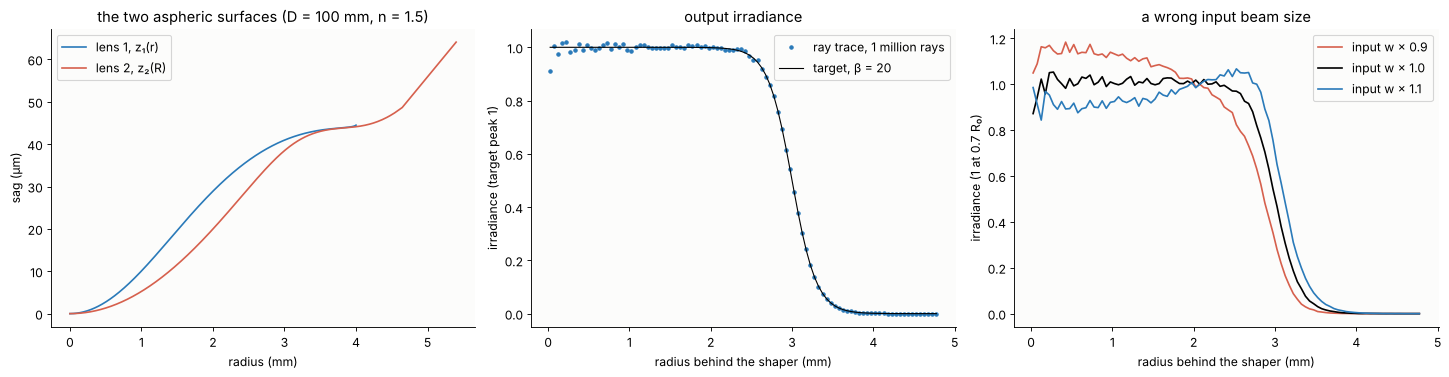

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6), layout="constrained")
ax[0].plot(r, 1e3*z_1, color=BLUE, label="lens 1, z₁(r)")
ax[0].plot(R_of_r, 1e3*z_2, color=RED, label="lens 2, z₂(R)")
ax[0].set_xlabel("radius (mm)")
ax[0].set_ylabel("sag (µm)")
ax[0].set_title("the two aspheric surfaces (D = 100 mm, n = 1.5)")
ax[0].legend()
ax[1].plot(Rc, E2/norm2, ".", color=BLUE, label="ray trace, 1 million rays")
ax[1].plot(Rc, E2_target, color="k", lw=1, label="target, β = {}".format(BETA))
ax[1].set_xlabel("radius behind the shaper (mm)")
ax[1].set_ylabel("irradiance (target peak 1)")
ax[1].set_title("output irradiance")
ax[1].legend()
for f_w, c in zip((0.9, 1.0, 1.1), (RED, "k", BLUE)):
    E = mismatch[f_w]
    ax[2].plot(Rc, E/E[np.argmin(np.abs(Rc - 0.7*R_0))], color=c, label="input w × {:.1f}".format(f_w))
ax[2].set_xlabel("radius behind the shaper (mm)")
ax[2].set_ylabel("irradiance (1 at 0.7 R₀)")
ax[2].set_title("a wrong input beam size")
ax[2].legend()
plt.show()

The surfaces are shallow: 44.5 µm of sag on the first one and 64.1 µm on
the second. Behind the shaper the largest ray angle is 2.2e-6 rad and the
optical paths of all rays agree to 1.8e-4 waves, so the output is
collimated with a plane wavefront. The irradiance follows the target to
1.6 % rms inside $0.8R_0$, which is the shot noise of the ray count
(1.5 %).

The design is only right for its input. A beam 10 % too small has too much
power near the axis, and the centre is 13 % brighter than the plateau at
$0.7R_0$. A beam 10 % too large leaves the centre 7 % darker (the design
beam gives 0.97 here, the rest is noise). Gaussian to flat-top shapers
need the beam size to within a few percent, and they need it centred.

## 3. Wave optics behind the shaper

Behind the shaper the field has the amplitude $\sqrt{E_\mathrm{out}}$ and a
plane phase. It is propagated with the angular spectrum method (as in the
propagation notebooks) to see how long the flat top stays flat. The
Fresnel number $N_F = R_0^2/(\lambda z)$ says how many Fresnel zones the
beam covers: about 17 at 1 m for 532 nm. A sharp edge sends ripples from
the edge to the centre. A soft edge has less high spatial frequency
content and diffracts less.

In [7]:
# wave optics behind the shaper: amplitude sqrt(E_out), plane phase (the ray trace showed a plane wavefront)
N3, DX3 = 1024, 0.024                 # mm: a 24.6 mm window
x3 = (np.arange(N3) - N3//2)*DX3
X3, Y3 = np.meshgrid(x3, x3, indexing="ij")
R3 = np.hypot(X3, Y3)
fx = np.fft.fftfreq(N3, DX3)
FX, FY = np.meshgrid(fx, fx, indexing="ij")
kz = 2*np.pi*np.sqrt(np.maximum(0, 1/WL**2 - FX**2 - FY**2))
zs3 = np.array([0, 250, 500, 1000, 2000, 4000.0])   # mm
prop = {}
for b in (20, 60):
    U0 = np.sqrt(ff.fermi_dirac(R3, R_0, b))
    F0 = np.fft.fft2(U0)
    prop[b] = [np.abs(np.fft.ifft2(F0*np.exp(1j*kz*z)))**2 for z in zs3]
flat = {}
for b in (20, 60):
    flat[b] = [np.std(I[R3 < 0.8*R_0])/np.mean(I[R3 < 0.8*R_0]) for I in prop[b]]
    print("beta = {}: rms/mean within 0.8 R_0 at z = {} m: {}".format(
        b, (zs3/1000).tolist(), np.round(flat[b], 3).tolist()))
print("Fresnel number R_0^2/(lambda z) at 1 m: {:.0f}".format(R_0**2/(WL*1000)))

beta = 20: rms/mean within 0.8 R_0 at z = [0.0, 0.25, 0.5, 1.0, 2.0, 4.0] m: [0.004, 0.003, 0.002, 0.01, 0.044, 0.096]
beta = 60: rms/mean within 0.8 R_0 at z = [0.0, 0.25, 0.5, 1.0, 2.0, 4.0] m: [0.0, 0.002, 0.021, 0.082, 0.159, 0.202]
Fresnel number R_0^2/(lambda z) at 1 m: 17


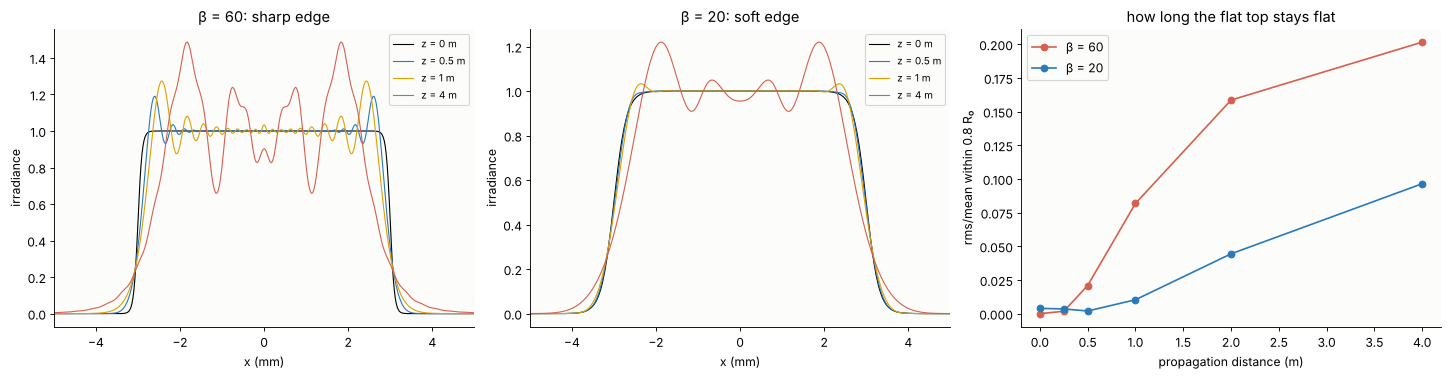

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6), layout="constrained")
row = N3//2
for a, b in zip(ax[:2], (60, 20)):
    for z, I, c in zip(zs3[[0, 2, 3, 5]], [prop[b][k] for k in (0, 2, 3, 5)], ("k", BLUE, ORANGE, RED)):
        a.plot(x3, I[:, row], color=c, lw=1, label="z = {:g} m".format(z/1000))
    a.set_xlim(-5, 5)
    a.set_xlabel("x (mm)")
    a.set_ylabel("irradiance")
    a.set_title("β = {}: {} edge".format(b, "sharp" if b == 60 else "soft"))
    a.legend(fontsize=9)
for b, c in ((60, RED), (20, BLUE)):
    ax[2].plot(zs3/1000, flat[b], "o-", color=c, label="β = {}".format(b))
ax[2].set_xlabel("propagation distance (m)")
ax[2].set_ylabel("rms/mean within 0.8 R₀")
ax[2].set_title("how long the flat top stays flat")
ax[2].legend()
plt.show()

At the shaper the sharp edge ($\beta = 60$) has the flatter plateau (rms
deviation 0 against 0.4 % for $\beta = 20$ within $0.8R_0$). Already at
0.5 m it is worse (2.1 % against 0.2 %), and at 1 m the ripple from the
edge is 8.2 % against 1.0 %. At 4 m the sharp flat top has 20 % rms
ripple and the soft one 9.6 %. This is why practical shapers specify a
soft edge: the flat region is a little smaller, but it stays flat over a
much longer working distance.

## 4. Freeform shaping and optimal transport

Without rotational symmetry the ray map $\mathbf T(x, y)$ is a map of the
plane onto the plane, and energy conservation becomes

$$a(\mathbf x) = b(\mathbf T(\mathbf x))\,\det\nabla\mathbf T(\mathbf x),$$

for the input irradiance $a$ and the target irradiance $b$. One equation
for two unknown functions has many solutions. A ray map that a smooth
surface can realize must be (nearly) curl free, and the natural choice is
the gradient of a convex function, $\mathbf T = \nabla\phi$. The equation
then becomes the Monge–Ampère equation

$$\det\nabla^2\phi = \frac{a(\mathbf x)}{b(\nabla\phi(\mathbf x))}.$$

Brenier's theorem says that its solution is the optimal transport map
for the quadratic cost $|\mathbf x - \mathbf T|^2$: of all ways to move
the input power onto the target, it moves it the least. `ot_map()` solves
the discrete transport problem between the two grids with the entropic
Sinkhorn method (in the log domain, with a separable kernel and a
shrinking regularization $\varepsilon$) and takes the barycentre of the
target cells each source cell sends power to.

The surface comes next. A plano-freeform lens gets a collimated beam
through its flat face, and the freeform exit surface $z(x, y)$ refracts the
ray at $(x, y)$ into the direction $\mathbf d$ towards $\mathbf T(x, y)$ on
a screen at the distance $L$. Snell's law in vector form gives the slope
the surface must have there,

$$\nabla z = \frac{(d_x, d_y)}{n - d_z},$$

and `integrate_gradient()` finds the surface whose gradient fits this in
the least squares sense. Because $\mathbf d$ depends on $z$, this is
iterated a few times. The sketch shows the arrangement.

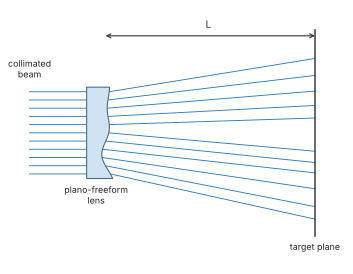

In [9]:
fig, ax = plt.subplots(figsize=(12, 4.2))
sketch.freeform_projection(ax)
plt.show()

In [10]:
N_OT, A4, W4, L4, H4 = 64, 6.0, 4.0, 200.0, 30.0   # grid, half aperture, beam 1/e^2 radius, distance, target half width (mm)
x4 = np.linspace(-A4, A4, N_OT)
X4, Y4 = np.meshgrid(x4, x4, indexing="ij")
a4 = np.exp(-2*(X4**2 + Y4**2)/W4**2)
y4 = np.linspace(-H4, H4, N_OT)
t0 = time.time()
Tx_sq, Ty_sq, err_sq = ff.ot_map(a4, (x4, x4), np.ones((N_OT, N_OT)), (y4, y4))
t_ot = time.time() - t0
# for product densities the optimal map is a product of 1D maps (erf of the Gaussian)
from scipy.special import erf
edge = H4 + (y4[1] - y4[0])/2
T1 = edge*erf(np.sqrt(2)*x4/W4)/erf(np.sqrt(2)*A4/W4)
print("Gaussian to square: Sinkhorn in {:.1f} s, marginal error {:.0e}; against the 1D map within |x| < 0.8 A: rms {:.2f} mm "
      "(target cells {:.2f} mm); |Tx - Ty^T| max {:.0e} mm".format(
          t_ot, err_sq, np.sqrt(np.mean((Tx_sq - T1[:, None])[np.abs(x4) < 0.8*A4][:, np.abs(x4) < 0.8*A4]**2)),
          y4[1] - y4[0], np.max(np.abs(Tx_sq - Ty_sq.T))))
z_sq = ff.freeform_lens(x4, x4, Tx_sq, Ty_sq, N_GLASS, L4)

def freeform_system(z):
    return rt.System([rt.Surface(np.inf, 5.0, n_after=N_GLASS, semi_diameter=10.0),
                      ff.TabulatedSurface(x=x4, y=x4, z=z, thickness=L4, n_after=1.0)],
                     0, WL, object_distance=10.0)

def trace_to_target(z, n_rays=2_000_000, divergence=0.0):
    xy = rng.normal(0, W4/2, (n_rays, 2))
    xy = xy[np.all(np.abs(xy) < A4, axis=1)]
    d = np.column_stack([divergence*rng.standard_normal((len(xy), 2)), np.ones(len(xy))])
    d /= np.linalg.norm(d, axis=1)[:, None]
    B = freeform_system(z).trace(rt.Rays(np.column_stack([xy, np.full(len(xy), -10.0)]), d, np.zeros(len(xy))))
    return B.points[-1], len(xy)

rng_edges = [(-H4 - (y4[1] - y4[0])/2, H4 + (y4[1] - y4[0])/2)]*2
Q_sq, n_sq = trace_to_target(z_sq)
E_sq, _, _ = il.irradiance_map(Q_sq, 1.0/n_sq, N_OT, rng_edges)
core = (slice(4, -4), slice(4, -4))
counts = E_sq*(y4[1] - y4[0])**2*n_sq
print("square flat top: sag from {:.0f} to {:.0f} um; rms/mean of the traced irradiance inside (4 cells from the edge) {:.1%}, "
      "shot noise {:.1%}".format(1e3*z_sq.min(), 1e3*z_sq.max(), np.std(E_sq[core])/np.mean(E_sq[core]),
                                 np.sqrt(np.mean(1/counts[core]))))

Gaussian to square: Sinkhorn in 2.9 s, marginal error 2e-12; against the 1D map within |x| < 0.8 A: rms 0.07 mm (target cells 0.95 mm); |Tx - Ty^T| max 1e-10 mm


square flat top: sag from 1 to 2256 um; rms/mean of the traced irradiance inside (4 cells from the edge) 4.7%, shot noise 4.5%


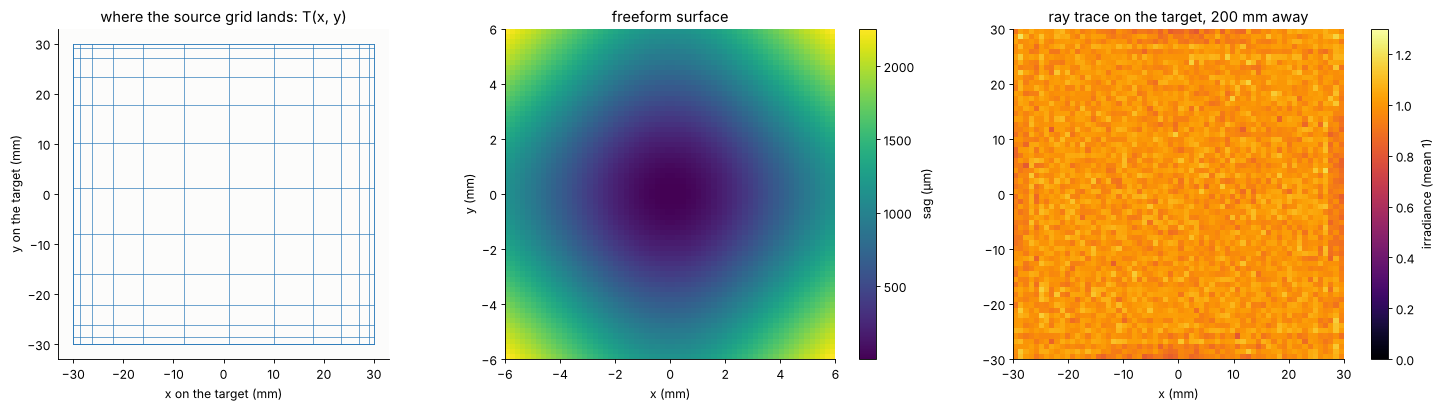

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5), layout="constrained")
step = 4
ax[0].plot(Tx_sq[::step, ::step], Ty_sq[::step, ::step], color=BLUE, lw=0.6)
ax[0].plot(Tx_sq[::step, ::step].T, Ty_sq[::step, ::step].T, color=BLUE, lw=0.6)
ax[0].set_aspect("equal")
ax[0].set_xlabel("x on the target (mm)")
ax[0].set_ylabel("y on the target (mm)")
ax[0].set_title("where the source grid lands: T(x, y)")
im = ax[1].imshow(1e3*z_sq.T, extent=[-A4, A4, -A4, A4], origin="lower", cmap="viridis")
fig.colorbar(im, ax=ax[1], label="sag (µm)")
ax[1].set_title("freeform surface")
ax[1].set_xlabel("x (mm)")
ax[1].set_ylabel("y (mm)")
im = ax[2].imshow(E_sq.T/np.mean(E_sq[core]), extent=[-H4, H4, -H4, H4], origin="lower", cmap="inferno", vmin=0, vmax=1.3)
fig.colorbar(im, ax=ax[2], label="irradiance (mean 1)")
ax[2].set_title("ray trace on the target, 200 mm away")
ax[2].set_xlabel("x (mm)")
plt.show()

Here a Gaussian with $w = 4$ mm on a 12 mm square aperture is sent onto a
60 mm square 200 mm away, on a 64 × 64 grid. Sinkhorn needs a few seconds
and fits both marginals to 2e-12. For two product densities the optimal
map is a product of two 1D maps, $T_x = T_x(x)$ from the error function.
The computed map follows it to 0.07 mm rms inside $0.8A$, much less than
the 0.95 mm target cell, and it is symmetric ($|T_x - T_y^\top|$ of
1e-10 mm).

The surface rises from 1 µm to 2.3 mm: it is mostly a strong negative
lens that spreads the 12 mm beam over 60 mm, with the extra shape that
moves the bright centre outwards. Traced with 2 million rays, the square is flat to 4.7 % rms (shot noise 4.5 %).

## 5. An arbitrary target

Nothing in the method needs the target to be simple. The target below is
a picture of the letters "Aβ" on a 15 % floor. The floor matters: optimal
transport onto a target with dark gaps can be discontinuous, and then no
smooth surface realizes it. The lens is traced again with 2 million
rays.

In [12]:
fig_t = plt.figure(figsize=(2, 2), dpi=N_OT/2)
fig_t.text(0.5, 0.5, "Aβ", ha="center", va="center", fontsize=60, weight="bold")
fig_t.canvas.draw()
img = 1 - np.asarray(fig_t.canvas.buffer_rgba())[:, :, 0].astype(float)/255
plt.close(fig_t)
target = 0.15 + gaussian_filter(img[::-1].T, 0.7)     # axis 0 = x; a 15 % floor keeps the support convex
t0 = time.time()
Tx_im, Ty_im, err_im = ff.ot_map(a4, (x4, x4), target, (y4, y4))
t_ot = time.time() - t0
curl = np.gradient(Tx_im, x4, axis=1) - np.gradient(Ty_im, x4, axis=0)
print("image: Sinkhorn in {:.1f} s, marginal error {:.0e}; curl of the map / its gradient: {:.1%} rms".format(
    t_ot, err_im, np.sqrt(np.mean(curl**2))/np.sqrt(np.mean(np.gradient(Tx_im, x4, axis=0)**2))))
z_im = ff.freeform_lens(x4, x4, Tx_im, Ty_im, N_GLASS, L4)
# landing points of the grid rays against the map
G = freeform_system(z_im).trace(rt.Rays(np.column_stack([X4.ravel(), Y4.ravel(), np.full(X4.size, -10.0)]),
                                        np.tile([0, 0, 1.0], (X4.size, 1)), np.zeros(X4.size))).points[-1]
land = np.hypot(G[:, 0] - Tx_im.ravel(), G[:, 1] - Ty_im.ravel())
print("landing error of the grid rays: rms {:.2f} mm, max {:.2f} mm (target cell {:.2f} mm)".format(
    np.sqrt(np.mean(land**2)), land.max(), y4[1] - y4[0]))
Q_im, n_im = trace_to_target(z_im)
E_im, _, _ = il.irradiance_map(Q_im, 1.0/n_im, N_OT, rng_edges)
tgt = target/target.sum()/(y4[1] - y4[0])**2
print("traced image: correlation with the target {:.3f}, rms deviation {:.1%} of the mean".format(
    np.corrcoef(E_im.ravel(), tgt.ravel())[0, 1], np.sqrt(np.mean((E_im - tgt)**2))/np.mean(tgt)))
steep = np.hypot(*np.gradient(tgt)) > 0.1*np.hypot(*np.gradient(tgt)).max()
print("cells next to a letter edge: {:.0%} of the target, {:.0%} of the squared deviation".format(
    steep.mean(), np.sum(((E_im - tgt)**2)[steep])/np.sum((E_im - tgt)**2)))
print("sag from {:.0f} to {:.0f} um".format(1e3*z_im.min(), 1e3*z_im.max()))

image: Sinkhorn in 3.0 s, marginal error 2e-13; curl of the map / its gradient: 2.1% rms
landing error of the grid rays: rms 0.12 mm, max 0.55 mm (target cell 0.95 mm)


traced image: correlation with the target 0.986, rms deviation 18.0% of the mean
cells next to a letter edge: 17% of the target, 85% of the squared deviation
sag from -1 to 2065 um


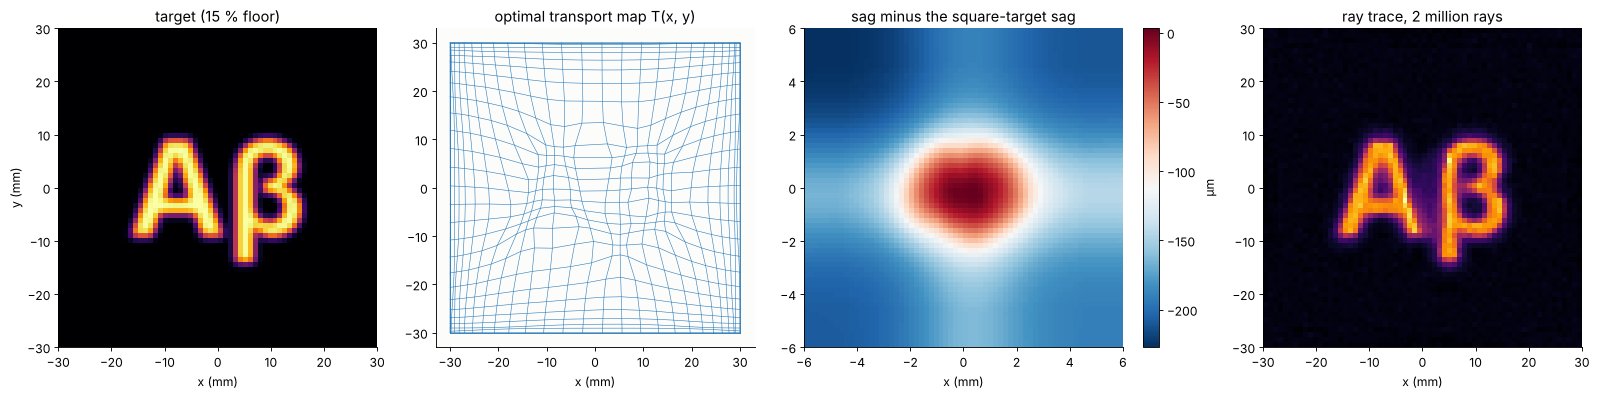

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.8), layout="constrained")
ax[0].imshow(target.T, extent=[-H4, H4, -H4, H4], origin="lower", cmap="inferno")
ax[0].set_title("target (15 % floor)")
ax[0].set_xlabel("x (mm)")
ax[0].set_ylabel("y (mm)")
ax[1].plot(Tx_im[::2, ::2], Ty_im[::2, ::2], color=BLUE, lw=0.5)
ax[1].plot(Tx_im[::2, ::2].T, Ty_im[::2, ::2].T, color=BLUE, lw=0.5)
ax[1].set_aspect("equal")
ax[1].set_title("optimal transport map T(x, y)")
ax[1].set_xlabel("x (mm)")
im = ax[2].imshow(1e3*(z_im - z_sq).T, extent=[-A4, A4, -A4, A4], origin="lower", cmap="RdBu_r")
fig.colorbar(im, ax=ax[2], label="µm")
ax[2].set_title("sag minus the square-target sag")
ax[2].set_xlabel("x (mm)")
ax[3].imshow(E_im.T, extent=[-H4, H4, -H4, H4], origin="lower", cmap="inferno")
ax[3].set_title("ray trace, 2 million rays")
ax[3].set_xlabel("x (mm)")
plt.show()

Sinkhorn converged in a few seconds. The curl of the map is 2.1 % of its
gradient, small enough for a surface: the grid rays land 0.12 mm rms
from where the map sends them (0.55 mm at most, against a 0.95 mm target
cell). The traced picture correlates with the target to 0.986. Its rms
deviation is 18 % of the mean, and 85 % of the squared deviation sits in
the 17 % of the cells next to a letter edge. There the step from the
floor to the full brightness falls into one or two cells and is blurred
by the regularization of the map. The difference to the lens for the
square (third panel) is what writes the letters onto the screen.

## 6. Divergence and étendue

The design assumed a perfectly collimated beam, a source of zero étendue.
A real source has a size and an angular spread, and each point of the
freeform then sends a small cone instead of a ray. On the screen at the
distance $L$ the picture is blurred by about $L\sigma$ for an rms angle
$\sigma$. This is the étendue limit of notebook 83 again: a small, sharp
picture needs a beam of small étendue. Lasers can be shaped into fine
detail, while an LED shaper (an étendue many orders larger) can only set
the broad distribution, which is why LED freeforms aim at smooth targets.

In [14]:
divs = [0.0, 0.005, 0.015]       # rms angle of the input rays (rad)
E_div = {}
for dv in divs:
    Q, nq = trace_to_target(z_im, divergence=dv)
    E_div[dv], _, _ = il.irradiance_map(Q, 1.0/nq, N_OT, rng_edges)
    print("input divergence {:4.1f} mrad rms (blur L sigma = {:.1f} mm): correlation with the target {:.3f}".format(
        1e3*dv, L4*dv, np.corrcoef(E_div[dv].ravel(), tgt.ravel())[0, 1]))
print("stroke width of the letters: about {:.0f} mm".format(np.sum(img[N_OT//2] > 0.5)*(y4[1] - y4[0])/2))

input divergence  0.0 mrad rms (blur L sigma = 0.0 mm): correlation with the target 0.986


input divergence  5.0 mrad rms (blur L sigma = 1.0 mm): correlation with the target 0.969


input divergence 15.0 mrad rms (blur L sigma = 3.0 mm): correlation with the target 0.816
stroke width of the letters: about 8 mm


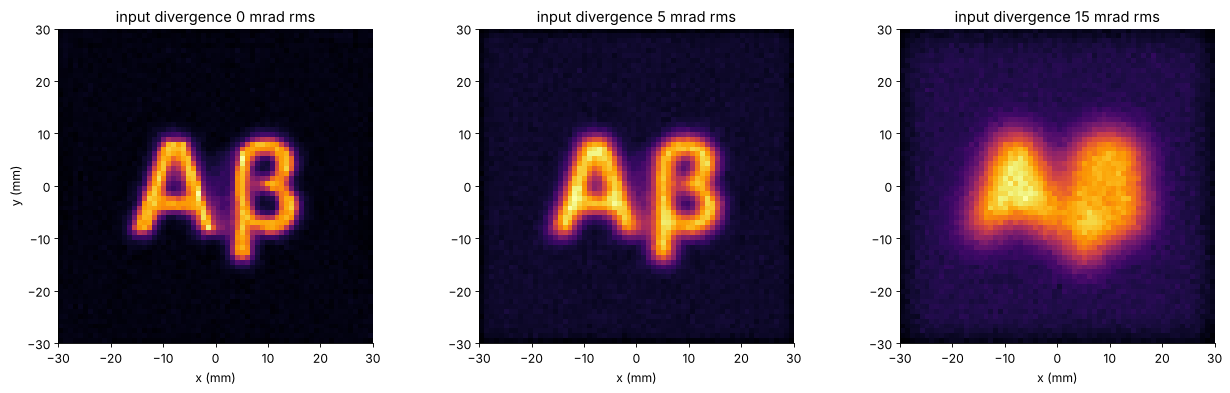

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), layout="constrained")
for a, dv in zip(ax, divs):
    a.imshow(E_div[dv].T, extent=[-H4, H4, -H4, H4], origin="lower", cmap="inferno")
    a.set_title("input divergence {:.0f} mrad rms".format(1e3*dv))
    a.set_xlabel("x (mm)")
ax[0].set_ylabel("y (mm)")
plt.show()

With 5 mrad rms the blur is 1 mm, about one target cell, and the
correlation drops only from 0.986 to 0.969. With 15 mrad the blur of 3 mm
is a large part of the 8 mm strokes, the letters smear out and the
correlation falls to 0.816. A design for a source of finite size would
deconvolve the target first or, better, design for the extended source
directly.

## Summary

- Energy conservation fixes the ray map of a rotationally symmetric
  shaper. Equal enclosed power gives $R(r)$, in closed form for a Gaussian
  to a sharp flat top.
- Two aspheres, one to redistribute and one to recollimate, turn a
  Gaussian into a collimated flat top with a plane wavefront. Equal
  optical path and Snell's law give both surfaces. They need the right
  input beam size: 10 % off moves the centre by 7–13 %.
- Sharp flat tops diffract into ripples within a fraction of a metre.
  Soft (Fermi–Dirac) edges keep the plateau flat much longer.
- Without symmetry the ray map solves the Monge–Ampère equation. It is
  the optimal transport map for the quadratic cost, which entropic
  Sinkhorn finds in seconds on a 64 × 64 grid. The freeform follows from
  the slopes Snell's law asks for, by least squares integration.
- The resolution of a freeform picture is limited by the target grid,
  the map's blur and above all the étendue of the source: the blur is
  the throw distance times the angular spread.

In [16]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 45 s


## References

- J. L. Kreuzer, "Coherent light optical system yielding an output beam
  of desired intensity distribution at a desired equiphase surface", US
  patent 3,476,463 (1969).
- J. A. Hoffnagle and C. M. Jefferson, "Design and performance of a
  refractive optical system that converts a Gaussian to a flattop beam",
  Appl. Opt. 39, 5488–5499 (2000).
- F. M. Dickey (ed.), *Laser Beam Shaping: Theory and Techniques*, 2nd
  ed., CRC Press (2014).
- C. Bösel and H. Gross, "Single freeform surface design for prescribed
  input wavefront and target irradiance", J. Opt. Soc. Am. A 34,
  1490–1499 (2017).
- R. Wu, L. Xu, P. Liu, Y. Zhang, Z. Zheng, H. Li and X. Liu, "Freeform
  illumination design: a nonlinear boundary problem for the elliptic
  Monge–Ampère equation", Opt. Lett. 38, 229–231 (2013).
- M. Cuturi, "Sinkhorn distances: lightspeed computation of optimal
  transport", NeurIPS 26 (2013).
- G. Peyré and M. Cuturi, "Computational optimal transport", Found.
  Trends Mach. Learn. 11, 355–607 (2019).
- R. T. Frankot and R. Chellappa, "A method for enforcing integrability
  in shape from shading algorithms", IEEE Trans. Pattern Anal. Mach.
  Intell. 10, 439–451 (1988).